# Assignment 2 Distribution Grid Simulation

## Notebook C

In [1]:
import pandapower as pp
import pandapower.plotting as plot
import pandas as pd
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)

GEN_DATA_PATH = "../Data/GenerationData_B.csv"
LOAD_DATA_PATH = "../Data/LoadData_B.csv"


#### Creating the C Dataset Grid Using Pandapower

Convert this code to fit the Grid C

In [2]:
# create empty net
net = pp.create_empty_network()

# create buses 0..17 (bus 0 is 20 kV, the rest are 0.4 kV)
buses = [pp.create_bus(net, vn_kv=20.0 if i==0 else 0.4, name=f"Bus {i}") for i in range(18)]

# create bus elements (use the first few buses as examples)
pp.create_ext_grid(net, bus=buses[0], vm_pu=1.02, name="Grid Connection")
for i in range(1, 18):
    pp.create_load(net, bus=buses[i], p_mw=0.1, q_mvar=0.005, name=f"Load {i}") # pyright: ignore[reportArgumentType]
    pp.create_sgen(net, bus=buses[i], p_mw=0.1, q_mvar=0.005, name=f"Sgen {i}") # type: ignore


# create branch elements
tid = pp.create_transformer(
    net, hv_bus=buses[0], lv_bus=buses[1], std_type="0.4 MVA 20/0.4 kV", name="Trafo"
)
# create primary branch: buses 1 -> 2 -> ... -> 8
for i in range(1, 8):
    pp.create_line(net, from_bus=buses[i], to_bus=buses[i+1], length_km=0.100, name=f"Line {i}-{i+1}", std_type="NAYY 4x50 SE")

# create second branch: connect bus 1 to bus 9, then 9 -> 10 -> ... -> 17
pp.create_line(net, from_bus=buses[1], to_bus=buses[9], length_km=0.100, name="Line 1-9", std_type="NAYY 4x50 SE")
for i in range(9, 17):
    pp.create_line(net, from_bus=buses[i], to_bus=buses[i+1], length_km=0.100, name=f"Line {i}-{i+1}", std_type="NAYY 4x50 SE")

No or insufficient geodata available --> Creating artificial coordinates. This may take some time


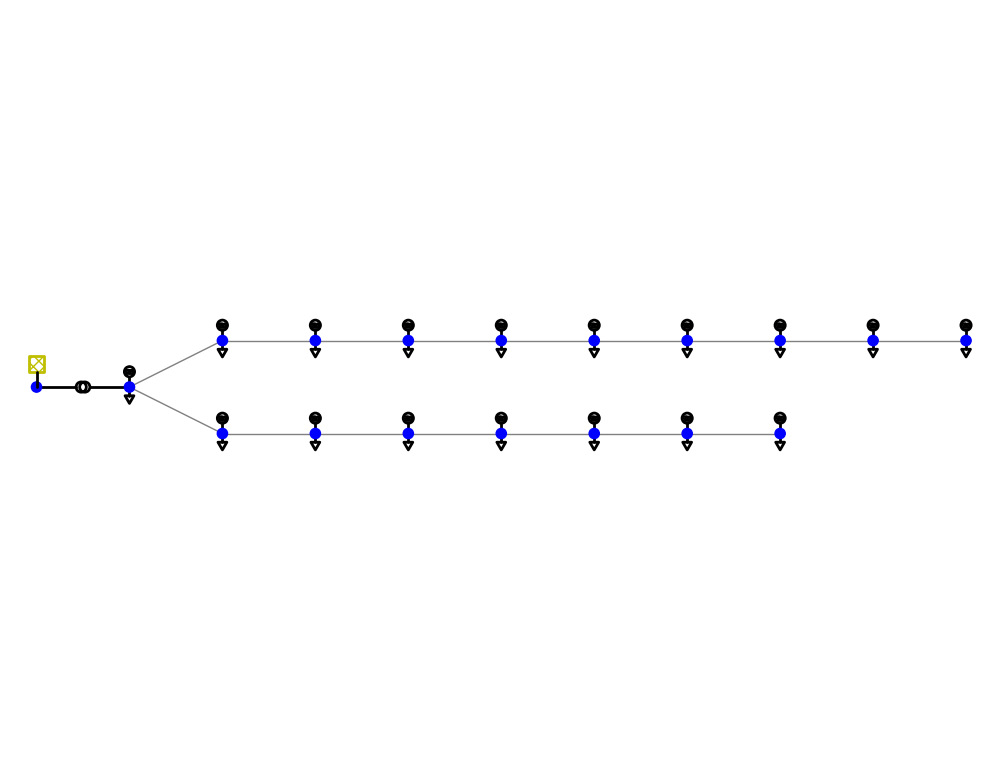

<Axes: >

In [3]:
plot.simple_plot(net, plot_loads=True, plot_sgens=True)

In [4]:
pp.runpp(net)
net.res_ext_grid

NUM_PROFILES = net.load.shape[0]

#### Algorithmic Optimization of Household Allocation

Find and rank the best load-generation pairs based on minimizing peak net load

In [5]:
from rank_best_pairs import rank_best_pairs
ranked_pairs = rank_best_pairs(
    gen_data_path=GEN_DATA_PATH,
    load_data_path=LOAD_DATA_PATH,
    num_profiles=NUM_PROFILES
)
print("Ranked load-generation pairs (best to worst):")
print(ranked_pairs)

Ranked load-generation pairs (best to worst):
[(8, 14), (12, 15), (11, 10), (15, 8), (1, 3), (5, 6), (9, 5), (6, 2), (0, 11), (16, 7), (14, 9), (3, 1), (2, 13), (4, 4), (7, 0), (10, 16), (13, 12)]


Rank a list of buses from "weakest" to "strongest" using the Short Circuit Impedance Method.

In [6]:
from grid_analyzer import rank_buses_by_impedance
residential_bus_indicies = list(range(1, NUM_PROFILES+1))  # buses 1 to 17 (excluding bus 0 which is the external grid)
ranked_buses = rank_buses_by_impedance(net, residential_bus_indicies)

Ranking buses by Short-Circuit Impedance (z_sc)...
Ranked Buses (Weakest to Strongest): [16, 15, 14, 7, 13, 6, 12, 5, 4, 11, 3, 10, 9, 2, 8, 1, 0]


Assign best load generation pairs to weakest bus. Create the "smart" allocation and calculate its sum of max loadings.

In [7]:
from first_guesses import create_smart_seed, create_round_robin_seed
from genetic_algorithm import calculate_fitness
smart_seed_allocation = create_smart_seed(
    ranked_pairs,
    ranked_buses
)

fitness_smart, max_smart = calculate_fitness(
    smart_seed_allocation,
    net,
    gen_data_path=GEN_DATA_PATH,
    load_data_path=LOAD_DATA_PATH
)
print(f"Smart Seed sum of max loadings: ", max_smart)

Creating smart seed allocation...
Smart seed allocation created.
Load Allocation: [13, 10, 4, 14, 0, 6, 5, 15, 7, 2, 3, 16, 9, 1, 11, 12, 8]
Generation Allocation: [12, 16, 4, 9, 11, 2, 6, 8, 0, 13, 1, 7, 5, 3, 10, 15, 14]


100%|██████████| 24/24 [00:00<00:00, 402.82it/s]

Smart Seed sum of max loadings:  95.6441046242102


Run Round Robin Allocation, to see if is gets a better result than Smart Seed Allocation. 

In [8]:
round_robin_allocation = create_round_robin_seed(
    gen_data_path=GEN_DATA_PATH,
    load_data_path=LOAD_DATA_PATH,
    num_profiles=NUM_PROFILES
)
fitness_rr, max_rr = calculate_fitness(
    round_robin_allocation,
    net,
    gen_data_path=GEN_DATA_PATH,
    load_data_path=LOAD_DATA_PATH
)
print(f"Round Robin sum of max loadings: ", max_rr)

100%|██████████| 24/24 [00:00<00:00, 313.98it/s]

Round Robin sum of max loadings:  88.972002578059


Run the genetic algorithm for grid B, using best first guess.

In [9]:
# Decide which initial allocation to use
if max_smart < max_rr:
    print("Using Smart Seed as initial allocation for GA.")
    initial_allocation = smart_seed_allocation
else:
    print("Using Round Robin Seed as initial allocation for GA.")
    initial_allocation = round_robin_allocation

from genetic_algorithm_C import run_genetic_algorithm
run_genetic_algorithm(
    net,
    gen_data_path=GEN_DATA_PATH,
    load_data_path=LOAD_DATA_PATH,
    initial_allocation=initial_allocation,
    population_size=50,
    num_generations=30,
    tournament_size=3,
    mutation_rate=0.1,
    crossover_rate=0.9
)


Using Round Robin Seed as initial allocation for GA.
--- Distribution Grid Genetic Algorithm Optimization Test ---
Distribution Grid:
 This pandapower network includes the following parameter tables:
   - bus (18 elements)
   - load (17 elements)
   - sgen (17 elements)
   - ext_grid (1 element)
   - line (16 elements)
   - trafo (1 element)
   - controller (4 elements)
   - bus_geodata (18 elements)
   - output_writer (1 element)
 and the following results tables:
   - res_bus (18 elements)
   - res_line (16 elements)
   - res_trafo (1 element)
   - res_ext_grid (1 element)
   - res_load (17 elements)
   - res_sgen (17 elements)
   - res_bus_sc (17 elements)
   - res_line_sc (16 elements)
   - res_trafo_sc (1 element)
   - res_ext_grid_sc (1 element)
   - res_sgen_sc (17 elements)

Base Allocation Test:
Load Allocation: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
Generation Allocation: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
([0, 1, 2, 3, 4, 5, 6, 7, 

100%|██████████| 24/24 [00:00<00:00, 265.49it/s]


Fitness: 0.00800926388649687, Sum Max Loading: 124.85541919600612

Initial Allocation Test:
Load Allocation: [13, 2, 12, 8, 14, 4, 11, 1, 9, 7, 10, 0, 3, 5, 15, 6, 16]
Generation Allocation: [13, 2, 12, 8, 14, 4, 11, 1, 9, 7, 10, 0, 3, 5, 15, 6, 16]


100%|██████████| 24/24 [00:00<00:00, 197.16it/s]


Fitness: 0.011239490750167802, Sum Max Loading: 88.972002578059

=== Distribution Grid Genetic Algorithm Optimization ===
CPUs available: 12
Using 50 allocations, evolving for 30 generations.
Creating initial population...
[([13, 2, 12, 8, 14, 4, 11, 1, 9, 7, 10, 0, 3, 5, 15, 6, 16], [13, 2, 12, 8, 14, 4, 11, 1, 9, 7, 10, 0, 3, 5, 15, 6, 16]), ([14, 0, 10, 12, 1, 9, 2, 6, 4, 5, 11, 16, 7, 15, 8, 13, 3], [5, 13, 15, 14, 16, 0, 8, 7, 11, 4, 12, 9, 2, 3, 1, 6, 10]), ([12, 4, 11, 14, 3, 15, 10, 1, 9, 16, 13, 8, 6, 0, 2, 7, 5], [0, 13, 8, 15, 11, 4, 9, 12, 5, 10, 6, 7, 16, 2, 14, 1, 3]), ([6, 14, 3, 1, 4, 8, 0, 5, 7, 12, 10, 2, 16, 11, 13, 15, 9], [10, 12, 16, 9, 4, 2, 7, 15, 14, 13, 5, 1, 11, 3, 6, 0, 8]), ([4, 15, 11, 7, 16, 9, 14, 6, 2, 13, 3, 10, 12, 8, 0, 1, 5], [9, 14, 5, 7, 6, 13, 8, 3, 0, 4, 2, 16, 1, 10, 15, 12, 11]), ([11, 12, 7, 9, 16, 0, 8, 3, 1, 4, 10, 6, 13, 2, 14, 15, 5], [1, 16, 4, 0, 5, 8, 7, 14, 11, 10, 15, 2, 6, 12, 13, 9, 3]), ([16, 13, 12, 7, 9, 1, 6, 10, 8, 5, 4, 2, 14